# BEP

# Pre-work

In [47]:
# imports

from pathlib import Path
import pandas as pd
import json
import ollama

from tqdm import tqdm

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [3]:
# config

tqdm.pandas()

In [4]:
# constants

ROOT_DIR = Path.cwd().parent
DATASET_DIR = ROOT_DIR / "datasets"

NOVIELLI_GOLD_STANDARD_DIR = DATASET_DIR / "novielli-gh-gold"
GH_GOLD_STANDARD = NOVIELLI_GOLD_STANDARD_DIR / "github_gold.csv"

COUTINHO_DIR = DATASET_DIR / "coutinho-sentiment-replication"
COUTINHO = COUTINHO_DIR / "dataset.json"

DEVA_INPUT_DIR = ROOT_DIR / "input" / "deva"
DEVA_OUTPUT_DIR = ROOT_DIR / "output" / "deva"

### Data collection (Novielli et al., 2020)

The dataset used by Novieli et al. is in CSV format, which makes it straight forward to create dataframes out of it.

In [5]:
df_novielli = pd.read_csv(GH_GOLD_STANDARD, sep=';', quotechar='"', encoding='utf-8')
df_novielli.columns = df_novielli.columns.str.lower()

# strip outer quote
df_novielli['text'] = df_novielli['text'].str.rstrip('"')
df_novielli

,id,polarity,text
0,4063186,neutral,No. I still see the wrong twins. * https://gi...
1,3894703,neutral,Reverted.
2,1971084,neutral,You can leave a queue while in queue ? (before...
3,1827828,positive,Didn't look at SpellTargetRestrictions XD
4,232603,neutral,Not sure about what kind of line lengths the p...
...,...,...,...
7117,963856,negative,"Yeah, I'm capable of working around it. A set..."
7118,5074806,positive,"Looks fine to me! On Jul 8, 2013, at 10:12 PM..."
7119,6359700,positive,Formula updated to address this (would be nice...
7120,3832826,positive,I trust you


### Data collection (Coutinho et al., 2024)

Since this dataset is in nested JSON format, we do some extra pre-processing to normalize it.

In [6]:
text = COUTINHO.read_text(encoding="utf-8")

if text.lstrip().startswith("["):
    data = json.loads(text)
else:
    try:
        data = [json.loads(line) for line in text.splitlines() if line.strip()]
    except json.JSONDecodeError:
        data = [json.loads(text)]

df_coutinho = pd.json_normalize(data, sep="_")

df_coutinho['polarity'] = df_coutinho['part2_aggregate_polarity'].where(
    df_coutinho['part2_aggregate_polarity'] != 'undefined',
    other=df_coutinho['discussion_polarity']
)
df_coutinho = df_coutinho[df_coutinho['polarity'].notna() & (df_coutinho['polarity'] != 'undefined')]

In [7]:
print(df_coutinho.shape)
df_coutinho.head(5)

(1791, 13)


,raw_message,clean_message,message_url,part2_aggregate_polarity,part2_aggregate_avg_confidence,part2_aggregate_agreement_type,tools_SentiStrength,tools_SentiStrengthSE,tools_SentiCR,tools_DEVA,tools_Senti4SD,discussion_polarity,polarity
0,@snicoll did you get a chance to follow up on ...,did you get a chance to follow up on the issue...,https://github.com/spring-projects/spring-boot...,neutral,4.333333,neuro_and_comp,neutral,neutral,neutral,neutral,neutral,NaN,neutral
1,Thank you for this PR. This is an interesting...,Thank you for this PR. This is an interesting...,https://github.com/google/guice/pull/1349#issu...,undefined,4.666667,undefined,negative,negative,negative,negative,neutral,neutral,neutral
2,"@mbhave, oh sorry for this, my fault, i'll be...",", oh sorry for this, my fault, i'll be more c...",https://github.com/spring-projects/spring-boot...,negative,5.000000,all,negative,negative,neutral,negative,neutral,NaN,negative
3,I've added `merge-with-amendments` so that we ...,I've added so that we can add documentation r...,https://github.com/spring-projects/spring-boot...,neutral,4.000000,comp_only,neutral,neutral,neutral,neutral,neutral,NaN,neutral
4,> @Primary and @ConditionalOnMissingBean. I th...,Applications can still use or qualifiers to g...,https://github.com/spring-projects/spring-boot...,negative,4.666667,all,negative,negative,neutral,negative,negative,NaN,negative


# DEVA Experiments

## Running DEVA collected datasets

DEVA expects an input .txt file with the message to be analyzed and its ID. To demonstrate, this is the example input they provide with the tool:
```
58204 Yes, that's correct.
32957 Challenge accepted! :)
45982 No problem.  It was my pleasure, and thanks for all the help.
63699 Still need tests  Neutral
14350 My mistake, sorry
```

It outputs the original input, as well as three extra columns: its valence score, its arousal score, and an emotional state label derived from the combination of both.

For the purposes of this replication study, however, the benchmark reduces sentiment to a three-class polarity task (positive, negative, neutral), so only the valence score is used. This maps directly to Novielli et al. replication's $±[1,3]$ schema:
- valence > +1 -> positive
- valence < -1 -> negative
- valence = ± 1 -> neutral

The output for the example input looks as follows:
```
58204 Yes, that's correct.  -2  -3    DEPRESSED
32957 Challenge accepted! :)  2   5   EXCITED
45982 No problem.  It was my pleasure, and thanks for all the help.   4   3   EXCITED
63699 Still need tests  Neutral   1   -2    NEUTRAL (LA)
14350 My mistake, sorry   -2  1   NEG VALENCE
```

Therefore, to run DEVA on the datasets collected above, we need to generate valid input, and then parse the output into dataframes.

In [8]:
def write_deva_input(df, output_path, id_col='id', text_col='text'):
    """Write a DEVA-compatible input .txt file from a dataframe."""
    df_out = df[[id_col, text_col]].drop_duplicates(subset=id_col)
    df_out.to_csv(output_path, sep='\t', header=False, index=False)

In [9]:
# novielli: already has 'id' and 'text' columns
write_deva_input(df_novielli, DEVA_INPUT_DIR / "nov_gh.txt")

# coutinho: needs synthetic IDs and uses 'clean_message' as text
df_coutinho_input = df_coutinho[['clean_message']].copy()
df_coutinho_input.insert(0, 'id', range(len(df_coutinho_input)))
write_deva_input(df_coutinho_input, DEVA_INPUT_DIR / "cou.txt", text_col='clean_message')

In [10]:
def parse_deva_output(filepath, dataset_label):
    rows = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip('\n').rsplit('\t', 3)  # split from right: [id+text, valence, arousal, label]
            if len(parts) == 4:
                id_and_text, valence, arousal, label = parts
                id_, text = id_and_text.split('\t', 1)  # split id from text on first tab
                rows.append({
                    'id': id_.strip(),
                    'text': text.strip(),
                    'valence': int(valence.strip()),
                    'arousal': int(arousal.strip()),
                    'deva_label': label.strip(),
                    'dataset': dataset_label
                })
    return pd.DataFrame(rows)

In [11]:
df_deva_novielli = parse_deva_output(DEVA_OUTPUT_DIR / "nov_gh_out.txt", "novielli")
df_deva_novielli.head(5)

,id,text,valence,arousal,deva_label,dataset
0,4063186,No. I still see the wrong twins. * https://gi...,-2,-2,DEPRESSED,novielli
1,3894703,Reverted.,1,1,NEUTRAL,novielli
2,1971084,You can leave a queue while in queue ? (before...,1,-3,NEUTRAL (LA),novielli
3,1827828,Didn't look at SpellTargetRestrictions XD,1,-2,NEUTRAL (LA),novielli
4,232603,Not sure about what kind of line lengths the p...,4,-3,RELAXED,novielli


In [12]:
df_deva_coutinho = parse_deva_output(DEVA_OUTPUT_DIR / "cou_out.txt", "coutinho")
df_deva_coutinho.head(5)

,id,text,valence,arousal,deva_label,dataset
0,0,did you get a chance to follow up on the issue...,1,-2,NEUTRAL (LA),coutinho
1,1,"""Thank you for this PR. This is an interestin...",-3,-4,DEPRESSED,coutinho
2,2,", oh sorry for this, my fault, i'll be more c...",-2,-3,DEPRESSED,coutinho
3,3,I've added so that we can add documentation r...,1,-3,NEUTRAL (LA),coutinho
4,4,Applications can still use or qualifiers to g...,-2,-4,DEPRESSED,coutinho


## Mapping DEVA results to polarity labels

As mentioned above, the following mapping is used:
- valence > +1 -> positive
- valence < -1 -> negative
- valence = ± 1 -> neutral

In [13]:
def valence_to_polarity(v):
    if v > 1:
        return 'positive'
    elif v < -1:
        return 'negative'
    else:
        return 'neutral'

In [14]:
df_deva_novielli['deva_polarity'] = df_deva_novielli['valence'].apply(valence_to_polarity)
df_deva_novielli

,id,text,valence,arousal,deva_label,dataset,deva_polarity
0,4063186,No. I still see the wrong twins. * https://gi...,-2,-2,DEPRESSED,novielli,negative
1,3894703,Reverted.,1,1,NEUTRAL,novielli,neutral
2,1971084,You can leave a queue while in queue ? (before...,1,-3,NEUTRAL (LA),novielli,neutral
3,1827828,Didn't look at SpellTargetRestrictions XD,1,-2,NEUTRAL (LA),novielli,neutral
4,232603,Not sure about what kind of line lengths the p...,4,-3,RELAXED,novielli,positive
...,...,...,...,...,...,...,...
7117,963856,"""Yeah, I'm capable of working around it. A se...",-3,-3,DEPRESSED,novielli,negative
7118,5074806,"Looks fine to me! On Jul 8, 2013, at 10:12 PM...",4,5,EXCITED,novielli,positive
7119,6359700,Formula updated to address this (would be nice...,1,-3,NEUTRAL (LA),novielli,neutral
7120,3832826,I trust you,-2,-2,DEPRESSED,novielli,negative


In [15]:
df_deva_coutinho['deva_polarity'] = df_deva_coutinho['valence'].apply(valence_to_polarity)
df_deva_coutinho

,id,text,valence,arousal,deva_label,dataset,deva_polarity
0,0,did you get a chance to follow up on the issue...,1,-2,NEUTRAL (LA),coutinho,neutral
1,1,"""Thank you for this PR. This is an interestin...",-3,-4,DEPRESSED,coutinho,negative
2,2,", oh sorry for this, my fault, i'll be more c...",-2,-3,DEPRESSED,coutinho,negative
3,3,I've added so that we can add documentation r...,1,-3,NEUTRAL (LA),coutinho,neutral
4,4,Applications can still use or qualifiers to g...,-2,-4,DEPRESSED,coutinho,negative
...,...,...,...,...,...,...,...
1786,1786,"Hmm, looks like r737027 corresponds to version...",1,-3,NEUTRAL (LA),coutinho,neutral
1787,1787,"<!-- First of all, thank you for your contribu...",-2,5,STRESSED,coutinho,negative
1788,1788,"there was a typo in the comment, also made a s...",1,-3,NEUTRAL (LA),coutinho,neutral
1789,1789,Fixed some typos. Added the ghost button type....,-2,-4,DEPRESSED,coutinho,negative


## Comparing resulting DEVA labels to original labels

In [16]:
def merge_with_gold(df_pred, df_gold, id_type=None):
    """Merge DEVA predictions with gold-standard labels on 'id'."""
    df = df_pred.copy()
    if id_type is not None:
        df['id'] = df['id'].astype(id_type)
    return df.merge(df_gold[['id', 'polarity']], on='id')

In [17]:
# novielli: gold IDs are ints, DEVA output IDs are strings
df_merged_novielli = merge_with_gold(df_deva_novielli, df_novielli, id_type=int)
df_merged_novielli

,id,text,valence,arousal,deva_label,dataset,deva_polarity,polarity
0,4063186,No. I still see the wrong twins. * https://gi...,-2,-2,DEPRESSED,novielli,negative,neutral
1,3894703,Reverted.,1,1,NEUTRAL,novielli,neutral,neutral
2,1971084,You can leave a queue while in queue ? (before...,1,-3,NEUTRAL (LA),novielli,neutral,neutral
3,1827828,Didn't look at SpellTargetRestrictions XD,1,-2,NEUTRAL (LA),novielli,neutral,positive
4,232603,Not sure about what kind of line lengths the p...,4,-3,RELAXED,novielli,positive,neutral
...,...,...,...,...,...,...,...,...
7117,963856,"""Yeah, I'm capable of working around it. A se...",-3,-3,DEPRESSED,novielli,negative,negative
7118,5074806,"Looks fine to me! On Jul 8, 2013, at 10:12 PM...",4,5,EXCITED,novielli,positive,positive
7119,6359700,Formula updated to address this (would be nice...,1,-3,NEUTRAL (LA),novielli,neutral,positive
7120,3832826,I trust you,-2,-2,DEPRESSED,novielli,negative,positive


In [18]:
# coutinho: build gold labels with synthetic IDs matching DEVA input
df_coutinho_labels = df_coutinho[['polarity']].copy()
df_coutinho_labels.insert(0, 'id', df_coutinho_labels.index.astype(str))
df_coutinho_labels = df_coutinho_labels[df_coutinho_labels['polarity'].notna() & (df_coutinho_labels['polarity'] != 'undefined')]

df_merged_coutinho = merge_with_gold(df_deva_coutinho, df_coutinho_labels)
df_merged_coutinho

,id,text,valence,arousal,deva_label,dataset,deva_polarity,polarity
0,0,did you get a chance to follow up on the issue...,1,-2,NEUTRAL (LA),coutinho,neutral,neutral
1,1,"""Thank you for this PR. This is an interestin...",-3,-4,DEPRESSED,coutinho,negative,neutral
2,2,", oh sorry for this, my fault, i'll be more c...",-2,-3,DEPRESSED,coutinho,negative,negative
3,3,I've added so that we can add documentation r...,1,-3,NEUTRAL (LA),coutinho,neutral,neutral
4,4,Applications can still use or qualifiers to g...,-2,-4,DEPRESSED,coutinho,negative,negative
...,...,...,...,...,...,...,...,...
1786,1786,"Hmm, looks like r737027 corresponds to version...",1,-3,NEUTRAL (LA),coutinho,neutral,negative
1787,1787,"<!-- First of all, thank you for your contribu...",-2,5,STRESSED,coutinho,negative,neutral
1788,1788,"there was a typo in the comment, also made a s...",1,-3,NEUTRAL (LA),coutinho,neutral,neutral
1789,1789,Fixed some typos. Added the ghost button type....,-2,-4,DEPRESSED,coutinho,negative,neutral


### Calculating precision, recall, F1 for DEVA results

For each class $cls$ of $classes=[positive, negative, neutral]$, we compute:
$$\text{precision}(cls) = \frac{TP}{TP + FP}\;\;\;\;\;\;\;\;\text{(of all messages predicted as class cls, the fraction that are truly cls)}$$
$$\text{recall}(cls) = \frac{TP}{TP + FN}\;\;\;\;\;\;\;\;\text{(of all messages that are truly of class cls, the fraction correctly identified)}$$
$$\text{f1}(cls) = 2\times\frac{\text{precision}(cls) \times \text{recall}(cls)}{\text{precision}(cls) + \text{recall}(cls)}\;\;\;\;\;\;\;\;\text{(harmonic mean of precision and recall)},$$
where for each class $cls$, TP is the number of messages correctly predicted as $cls$, FP is the number of messages incorrectly predicted as $cls$, and FN is the number of messages that belong to $cls$ but were predicted as a different class.

Moreover, for each metric, we compute macro averages and weighted averages:
$$\text{precision}_{\text{macro}} = \frac{1}{|classses|}\sum_{cls}\text{precision}(cls)$$
$$\text{precision}_{\text{weighted}} = \frac{\sum_{cls}\text{precision}(cls)\times|cls|}{\sum_{cls}|cls|}$$

We also aggregate TP, FP, FN across all classes to calculate an overall accuracy: micro-average. We use the following formulae:

$$\text{precision}_\text{micro}=\frac{\sum_{cls}TP_{cls}}{\sum_{cls}(TP_{cls}+FP_{cls}}$$
$$\text{recall}_\text{micro}=\frac{\sum_{cls}TP_{cls}}{\sum_{cls}(TP_{cls}+FN_{cls})}$$
$$\text{f1}_\text{micro}=2\times\frac{\text{precision}_\text{micro}\times \text{recall}_\text{micro}}{\text{precision}_\text{micro}+ \text{recall}_\text{micro}}$$

Note that in a multiclass setting where every sample gets exactly one label (as is in our case), $\sum TP_{cls} = \sum(TP_{cls} + FP_{cls}) = \sum(TP_{cls} + FN_{cls})$ (total number of samples). Therefore, $\text{precision}_\text{micro} = \text{recall}_\text{micro} = \text{f1}_\text{micro}$, which serves as an overall accuracy.

In [19]:
def compute_metrics(df, dataset_name, pred_col='deva_polarity', gold_col='polarity'):
    classes = ['positive', 'negative', 'neutral']
    rows = []

    for cls in classes:
        tp = ((df[pred_col] == cls) & (df[gold_col] == cls)).sum()
        fp = ((df[pred_col] == cls) & (df[gold_col] != cls)).sum()
        fn = ((df[pred_col] != cls) & (df[gold_col] == cls)).sum()
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        rows.append({
            'dataset': dataset_name,
            'class': cls,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'support': (df[gold_col] == cls).sum()
        })


    # macro average (simple mean across classes, like Coutinho et al.)
    macro = pd.DataFrame(rows)
    rows.append({
        'dataset': dataset_name,
        'class': 'macro avg',
        'precision': macro['precision'].mean(),
        'recall': macro['recall'].mean(),
        'f1': macro['f1'].mean(),
        'support': len(df)
    })

    # weighted average (mean weighted by class support)
    total = len(df)
    rows.append({
        'dataset': dataset_name,
        'class': 'weighted avg',
        'precision': (macro['precision'] * macro['support']).sum() / total,
        'recall':    (macro['recall']    * macro['support']).sum() / total,
        'f1':        (macro['f1']        * macro['support']).sum() / total,
        'support': total
    })

    # micro average (aggregate TP/FP/FN across all classes first)
    tp_sum = sum(((df[pred_col] == c) & (df[gold_col] == c)).sum() for c in classes)
    fp_sum = sum(((df[pred_col] == c) & (df[gold_col] != c)).sum() for c in classes)
    fn_sum = sum(((df[pred_col] != c) & (df[gold_col] == c)).sum() for c in classes)
    micro_p = tp_sum / (tp_sum + fp_sum) if (tp_sum + fp_sum) > 0 else 0
    micro_r = tp_sum / (tp_sum + fn_sum) if (tp_sum + fn_sum) > 0 else 0
    micro_f = 2 * micro_p * micro_r / (micro_p + micro_r) if (micro_p + micro_r) > 0 else 0
    rows.append({
        'dataset': dataset_name,
        'class': 'micro avg',
        'precision': micro_p,
        'recall': micro_r,
        'f1': micro_f,
        'support': total
    })


    return pd.DataFrame(rows)

In [20]:
metrics_novielli  = compute_metrics(df_merged_novielli,  'novielli')
metrics_coutinho  = compute_metrics(df_merged_coutinho, 'coutinho')

metrics_all = pd.concat([metrics_novielli, metrics_coutinho], ignore_index=True)
metrics_all

,dataset,class,precision,recall,f1,support
0,novielli,positive,0.702437,0.744660,0.722932,2013
1,novielli,negative,0.654648,0.722089,0.686717,2087
2,novielli,neutral,0.814222,0.723693,0.766293,3022
3,novielli,macro avg,0.723769,0.730147,0.725314,7122
4,novielli,weighted avg,0.735866,0.729149,0.730719,7122
5,novielli,micro avg,0.729149,0.729149,0.729149,7122
6,coutinho,positive,0.664903,0.723608,0.693015,521
7,coutinho,negative,0.484076,0.703704,0.573585,432
8,coutinho,neutral,0.798658,0.568019,0.663877,838
9,coutinho,macro avg,0.649212,0.665110,0.643492,1791


Note: the weighted average in the results is higher than the macro average mostly because the model seems to do much better on neutral text.

Note: the numbers are slightly different for the gs_gh set from the paper by Novielli et al. This is because I believe they run the experiemnts on the test set only (30% of the whole dataset), while I run it on the whole dataset. Moreover, the macro- and micro- averages are the same between both sets of results, confirming the validity of my replication.

| Dataset | Class        | Precision | Recall | F1    | Support |
|---------|--------------|-----------|--------|-------|---------|
| gs_gh   | Positive     | 0.702     | 0.745  | 0.723 | 2013    |
| gs_gh   | Negative     | 0.655     | 0.722  | 0.687 | 2087    |
| gs_gh   | Neutral      | 0.814     | 0.724  | 0.766 | 3022    |
| gs_gh   | Macro avg    | 0.724     | 0.730  | 0.725 | 7122    |
| gs_gh   | Weighted avg | 0.736     | 0.729  | 0.731 | 7122    |
| gs_gh   | Micro avg    | 0.729     | 0.729  | 0.729 | 7122    |
| cou     | Positive     | 0.665     | 0.724  | 0.693 | 521     |
| cou     | Negative     | 0.484     | 0.704  | 0.574 | 432     |
| cou     | Neutral      | 0.799     | 0.568  | 0.664 | 838     |
| cou     | Macro avg    | 0.649     | 0.665  | 0.643 | 1791    |
| cou     | Weighted avg | 0.684     | 0.646  | 0.651 | 1791    |
| cou     | Micro avg    | 0.646     | 0.646  | 0.646 | 1791    |

Some takeaways:
- for the Github Golden Standard dataset, DEVA does relatively well, with a macro-average F1 score of 0.725. Neutral is the easiest class to predict (F1 score of 0.766), which makes sense given lexicon-based tools tend to default toward neutral when no strong sentiment words are found
- for the Coutinho dataset, DEVA struggles more: a macro-average F1 score of just 0.643. The difference is especially striking in the negative class performance, as the precision is very low (0.484). This means that DEVA is over-predicting negative sentiment on this dataset, flagging many non-negative items as negative. Interestingly, Coutinho et al. state that _"unlike positive messages, negative messages were frequently very subtle, sometimes even employing irony or sarcasm, which has been noted by previous works as a problem for these tools"_. However, this is not really the case? As based on the results, it seems like DEVA is very trigger-happy with negative labelling, possibly due to technical vocabulary. **This is something worth analyzing perhaps.**
- on the GH GS dataset, DEVA is conservative with neutral labels: it has high precision but moderate recall. However, on the coutinho dataset, it has high precision but low recall -- meaning it's missing a lot of neutral cases, likely identifying them as negative. In both cases, DEVA under-predicts neutral, but it is quite precise when it does assign neutral.

**Why does DEVA seem to be so precise with neutral labels, but also so conservative?**
It's mostly down to how DEVA works under the hood. DEVA computes the overall valence score of a text as whichever of the max positive score or max negative score has the larger absolute value. So, for a text to be classified as neutral, every sentiment-bearing word must score +- 1, or no words match the dictionary at all. Any word scoring +2 or -2 anywhere in the text will pull the whole document to positive or negative, regardless of the neutral context.

# LLM Experiments

In [21]:
# config
MODELS = ["phi4:14b", "qwen3:8b", "qwen3.5:9b", "gemma3:12b", "gemma3:4b", "llama3.1:8b", "mistral:7b"]
N_SAMPLES = 200
SEED = 42
CACHE_DIR = ROOT_DIR / "output" / "llm_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
SYSTEM_PROMPT = """
Please perform Sentiment Classification task. Given the sentence from GitHub pull request code review comments, assign a sentiment label from ['negative', 'neutral', 'positive']. Return label only without any other text.
"""

In [32]:
def sample_balanced(df, polarity_col='polarity', n_per_class=N_SAMPLES, seed=SEED):
      return pd.concat([
          group.sample(min(n_per_class, len(group)), random_state=seed)
          for _, group in df.groupby(polarity_col)
      ]).reset_index(drop=True)

def cache_path(model: str) -> Path:
    safe_name = model.replace(":", "_").replace("/", "_")
    return CACHE_DIR / f"{safe_name}.csv"

def load_cache(model: str) -> dict:
    path = cache_path(model)
    if path.exists():
        df = pd.read_csv(path)
        return dict(zip(df["text"], df["label"]))
    return {}

def save_cache(model: str, results: dict):
    df = pd.DataFrame(list(results.items()), columns=["text", "label"])
    df.to_csv(cache_path(model), index=False)

MAX_CONSECUTIVE_ERRORS = 3

def classify(text: str, model: str) -> str:
    resp = ollama.chat(
        model=model,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user",   "content": f"Text: {text}"}
        ],
        options={"temperature": 0},
        think=False
    )
    raw = resp.message.content.strip().lower()
    for label in ("positive", "negative", "neutral"):
        if label in raw:
            return label
    return "unknown"

def classify_with_cache(texts, model: str) -> list[str]:
    cached = load_cache(model)
    results = dict(cached)  # copy
    labels = []
    consecutive_errors = 0

    for text in tqdm(texts, desc=model):
        if text in results:
            labels.append(results[text])
            consecutive_errors = 0
            continue

        try:
            label = classify(text, model)
            results[text] = label
            labels.append(label)
            consecutive_errors = 0
        except Exception as e:
            consecutive_errors += 1
            print(f"\n  Error on {model}: {e}")
            results[text] = "error"
            labels.append("error")

            if consecutive_errors >= MAX_CONSECUTIVE_ERRORS:
                print(f"  {MAX_CONSECUTIVE_ERRORS} consecutive errors — skipping {model}")
                labels.extend(["error"] * (len(texts) - len(labels)))
                break

        # save periodically (every 25 items)
        if len(labels) % 25 == 0:
            save_cache(model, results)

    save_cache(model, results)
    return labels

In [33]:
df_sample_nov = sample_balanced(df_novielli)
write_deva_input(df_sample_nov, '../input/deva/nov_gh_sample.txt')                                      

for model in MODELS:
    col = f"{model}_polarity"
    print(f"\n--- Running {model} ---")
    df_sample_nov[col] = classify_with_cache(df_sample_nov["text"].tolist(), model)
    n_errors = (df_sample_nov[col] == "error").sum()
    n_unknown = (df_sample_nov[col] == "unknown").sum()
    print(f"  Errors: {n_errors}, Unknown: {n_unknown}")


--- Running phi4:14b ---


phi4:14b: 100%|█████████████████████████████████| 600/600 [00:00<00:00, 605967.35it/s]


  Errors: 1, Unknown: 0

--- Running qwen3:8b ---


qwen3:8b: 100%|█████████████████████████████████| 600/600 [00:00<00:00, 573776.20it/s]


  Errors: 0, Unknown: 0

--- Running qwen3.5:9b ---


qwen3.5:9b: 100%|███████████████████████████████| 600/600 [00:00<00:00, 615752.97it/s]


... (5 outputs left out)

llama3.1:8b: 100%|██████████████████████████████| 600/600 [00:00<00:00, 489607.47it/s]


  Errors: 0, Unknown: 1

--- Running mistral:7b ---


mistral:7b: 100%|███████████████████████████████| 600/600 [00:00<00:00, 550554.01it/s]

  Errors: 0, Unknown: 0


In [34]:
df_sample_nov.head()

,id,polarity,text,phi4:14b_polarity,qwen3:8b_polarity,qwen3.5:9b_polarity,gemma3:12b_polarity,gemma3:4b_polarity,llama3.1:8b_polarity,mistral:7b_polarity
0,931642,negative,This loop will continue until it reaches the t...,error,neutral,neutral,negative,negative,negative,negative
1,1777632,negative,"Ah, sorry about that, noooow I get it. :( Goo...",neutral,neutral,neutral,positive,positive,negative,negative
2,321263,negative,"whoops sorry. I shouldn't commit while sick, ...",negative,negative,neutral,negative,negative,negative,negative
3,2098370,negative,"nope, when i run 0072 it also gives the error:...",negative,negative,neutral,negative,negative,negative,negative
4,4254523,negative,semi-colon cancer strikes again,negative,negative,negative,negative,negative,negative,negative


In [35]:
all_metrics = []
for model in MODELS:
    col = f"{model}_polarity"
    # skip models that errored out entirely
    valid = df_sample_nov[df_sample_nov[col] != "error"]
    if len(valid) < 10:
        print(f"Skipping {model} — too many errors ({len(df_sample_nov) - len(valid)}/{len(df_sample)})")
        continue
    metrics = compute_metrics(valid, f'novielli_sample ({model})', pred_col=col).round(3)
    all_metrics.append(metrics)

metrics_llm = pd.concat(all_metrics, ignore_index=True)
metrics_llm

,dataset,class,precision,recall,f1,support
0,novielli_sample (phi4:14b),positive,0.821,0.825,0.823,200
1,novielli_sample (phi4:14b),negative,0.700,0.774,0.735,199
2,novielli_sample (phi4:14b),neutral,0.669,0.595,0.630,200
3,novielli_sample (phi4:14b),macro avg,0.730,0.731,0.729,599
4,novielli_sample (phi4:14b),weighted avg,0.730,0.731,0.729,599
5,novielli_sample (phi4:14b),micro avg,0.731,0.731,0.731,599
6,novielli_sample (qwen3:8b),positive,0.924,0.670,0.777,200
7,novielli_sample (qwen3:8b),negative,0.729,0.765,0.746,200
8,novielli_sample (qwen3:8b),neutral,0.596,0.730,0.656,200
9,novielli_sample (qwen3:8b),macro avg,0.750,0.722,0.726,600


In [36]:
df_sample_cou = sample_balanced(df_coutinho)
df_sample_cou.insert(0, 'id', range(len(df_sample_cou)))
write_deva_input(df_sample_cou, '../input/deva/cou_gh_sample.txt', text_col='clean_message') 

for model in MODELS:
    col = f"{model}_polarity"
    print(f"\n--- Running {model} ---")
    df_sample_cou[col] = classify_with_cache(df_sample_cou["clean_message"].tolist(), model)
    n_errors = (df_sample_cou[col] == "error").sum()
    n_unknown = (df_sample_cou[col] == "unknown").sum()
    print(f"  Errors: {n_errors}, Unknown: {n_unknown}")


--- Running phi4:14b ---


phi4:14b: 100%|█████████████████████████████████| 600/600 [00:00<00:00, 518989.98it/s]


  Errors: 0, Unknown: 0

--- Running qwen3:8b ---


qwen3:8b: 100%|█████████████████████████████████| 600/600 [00:00<00:00, 494222.78it/s]


  Errors: 0, Unknown: 0

--- Running qwen3.5:9b ---


qwen3.5:9b: 100%|███████████████████████████████| 600/600 [00:00<00:00, 580660.45it/s]


... (5 outputs left out)

llama3.1:8b: 100%|██████████████████████████████| 600/600 [00:00<00:00, 549232.30it/s]


  Errors: 0, Unknown: 0

--- Running mistral:7b ---


mistral:7b: 100%|███████████████████████████████| 600/600 [00:00<00:00, 463886.16it/s]

  Errors: 0, Unknown: 0


In [37]:
all_metrics = []
for model in MODELS:
    col = f"{model}_polarity"
    # skip models that errored out entirely
    valid = df_sample_cou[df_sample_cou[col] != "error"]
    if len(valid) < 10:
        print(f"Skipping {model} — too many errors ({len(df_sample_cou) - len(valid)}/{len(df_sample_cou)})")
        continue
    metrics = compute_metrics(valid, f'coutinho_sample ({model})', pred_col=col).round(3)
    all_metrics.append(metrics)

metrics_llm = pd.concat(all_metrics, ignore_index=True)
metrics_llm

,dataset,class,precision,recall,f1,support
0,coutinho_sample (phi4:14b),positive,0.656,0.790,0.717,200
1,coutinho_sample (phi4:14b),negative,0.750,0.450,0.563,200
2,coutinho_sample (phi4:14b),neutral,0.477,0.570,0.519,200
3,coutinho_sample (phi4:14b),macro avg,0.628,0.603,0.599,600
4,coutinho_sample (phi4:14b),weighted avg,0.628,0.603,0.599,600
5,coutinho_sample (phi4:14b),micro avg,0.603,0.603,0.603,600
6,coutinho_sample (qwen3:8b),positive,0.847,0.580,0.688,200
7,coutinho_sample (qwen3:8b),negative,0.812,0.475,0.599,200
8,coutinho_sample (qwen3:8b),neutral,0.483,0.835,0.612,200
9,coutinho_sample (qwen3:8b),macro avg,0.714,0.630,0.633,600


In [44]:
df_deva_novielli_sampled = parse_deva_output(DEVA_OUTPUT_DIR / "nov_out_sampled.txt", "novielli")
df_deva_novielli_sampled['deva_polarity'] = df_deva_novielli_sampled['valence'].apply(valence_to_polarity)

df_deva_coutinho_sampled = parse_deva_output(DEVA_OUTPUT_DIR / "cou_out_sampled.txt", "coutinho")
df_deva_coutinho_sampled['deva_polarity'] = df_deva_coutinho_sampled['valence'].apply(valence_to_polarity)

# Novielli sample: merge DEVA results with gold labels
df_nov_sample_labels = df_sample_nov[['id', 'polarity']].copy()                                                                                 
df_nov_sample_labels['id'] = df_nov_sample_labels['id'].astype(str)                                                                             
df_merged_nov_sample = merge_with_gold(df_deva_novielli_sampled, df_nov_sample_labels)                                                          
                                                                                                                                                  
# Coutinho sample: merge DEVA results with gold labels
df_cou_sample_labels = df_sample_cou[['id', 'polarity']].copy()                                                                                 
df_cou_sample_labels['id'] = df_cou_sample_labels['id'].astype(str)                                                                             
df_merged_cou_sample = merge_with_gold(df_deva_coutinho_sampled, df_cou_sample_labels)
                                                                                                                                                  
# Compute metrics
metrics_deva_nov_sample = compute_metrics(df_merged_nov_sample, 'novielli_sample (DEVA)')                                                       
metrics_deva_cou_sample = compute_metrics(df_merged_cou_sample, 'coutinho_sample (DEVA)')                                                       
                                                                                                                                                  
pd.concat([metrics_deva_nov_sample, metrics_deva_cou_sample], ignore_index=True).round(3)

,dataset,class,precision,recall,f1,support
0,novielli_sample (DEVA),positive,0.775,0.775,0.775,200
1,novielli_sample (DEVA),negative,0.705,0.740,0.722,200
2,novielli_sample (DEVA),neutral,0.758,0.720,0.738,200
3,novielli_sample (DEVA),macro avg,0.746,0.745,0.745,600
4,novielli_sample (DEVA),weighted avg,0.746,0.745,0.745,600
5,novielli_sample (DEVA),micro avg,0.745,0.745,0.745,600
6,coutinho_sample (DEVA),positive,0.723,0.705,0.714,200
7,coutinho_sample (DEVA),negative,0.573,0.690,0.626,200
8,coutinho_sample (DEVA),neutral,0.640,0.525,0.577,200
9,coutinho_sample (DEVA),macro avg,0.645,0.640,0.639,600


In [48]:
labels = ['positive', 'neutral', 'negative']

def plot_confusion_matrix(y_true, y_pred, model_name, dataset_name):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    disp.plot(cmap='Blues')
    plt.title(f'{model_name} — {dataset_name}')
    plt.tight_layout()
    plt.show()

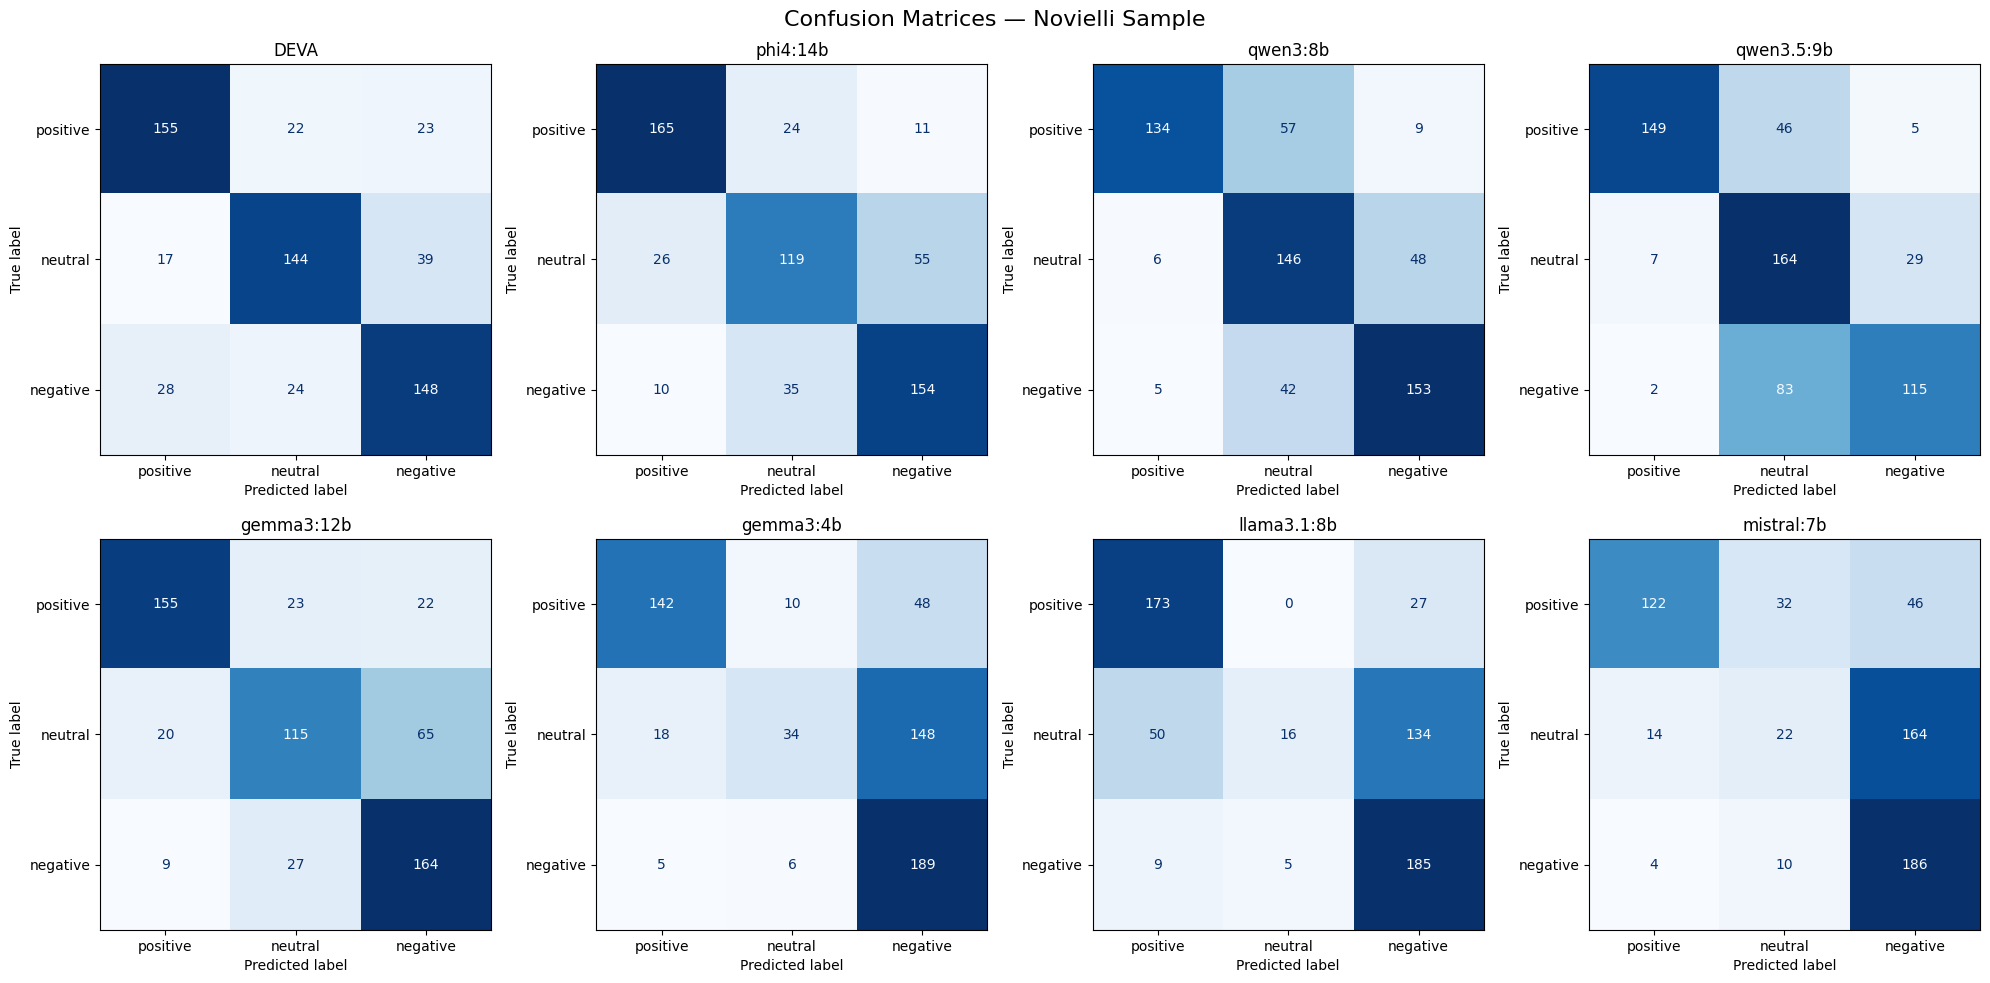

In [59]:
models = ['phi4:14b', 'qwen3:8b', 'qwen3.5:9b', 'gemma3:12b',
          'gemma3:4b', 'llama3.1:8b', 'mistral:7b']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

cm = confusion_matrix(df_merged_nov_sample['polarity'],                                                                                         
                      df_merged_nov_sample['deva_polarity'], labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)                                                                                        
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('DEVA')

for i, model in enumerate(models):
    cm = confusion_matrix(df_sample_nov['polarity'],
                          df_sample_nov[f'{model}_polarity'], labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    disp.plot(ax=axes[i + 1], cmap='Blues', colorbar=False)
    axes[i + 1].set_title(model)

fig.suptitle('Confusion Matrices — Novielli Sample', fontsize=16)
plt.tight_layout()
fig.savefig('../output/confusion_matrices_novielli.png', dpi=150, bbox_inches='tight')                                                          
plt.show()


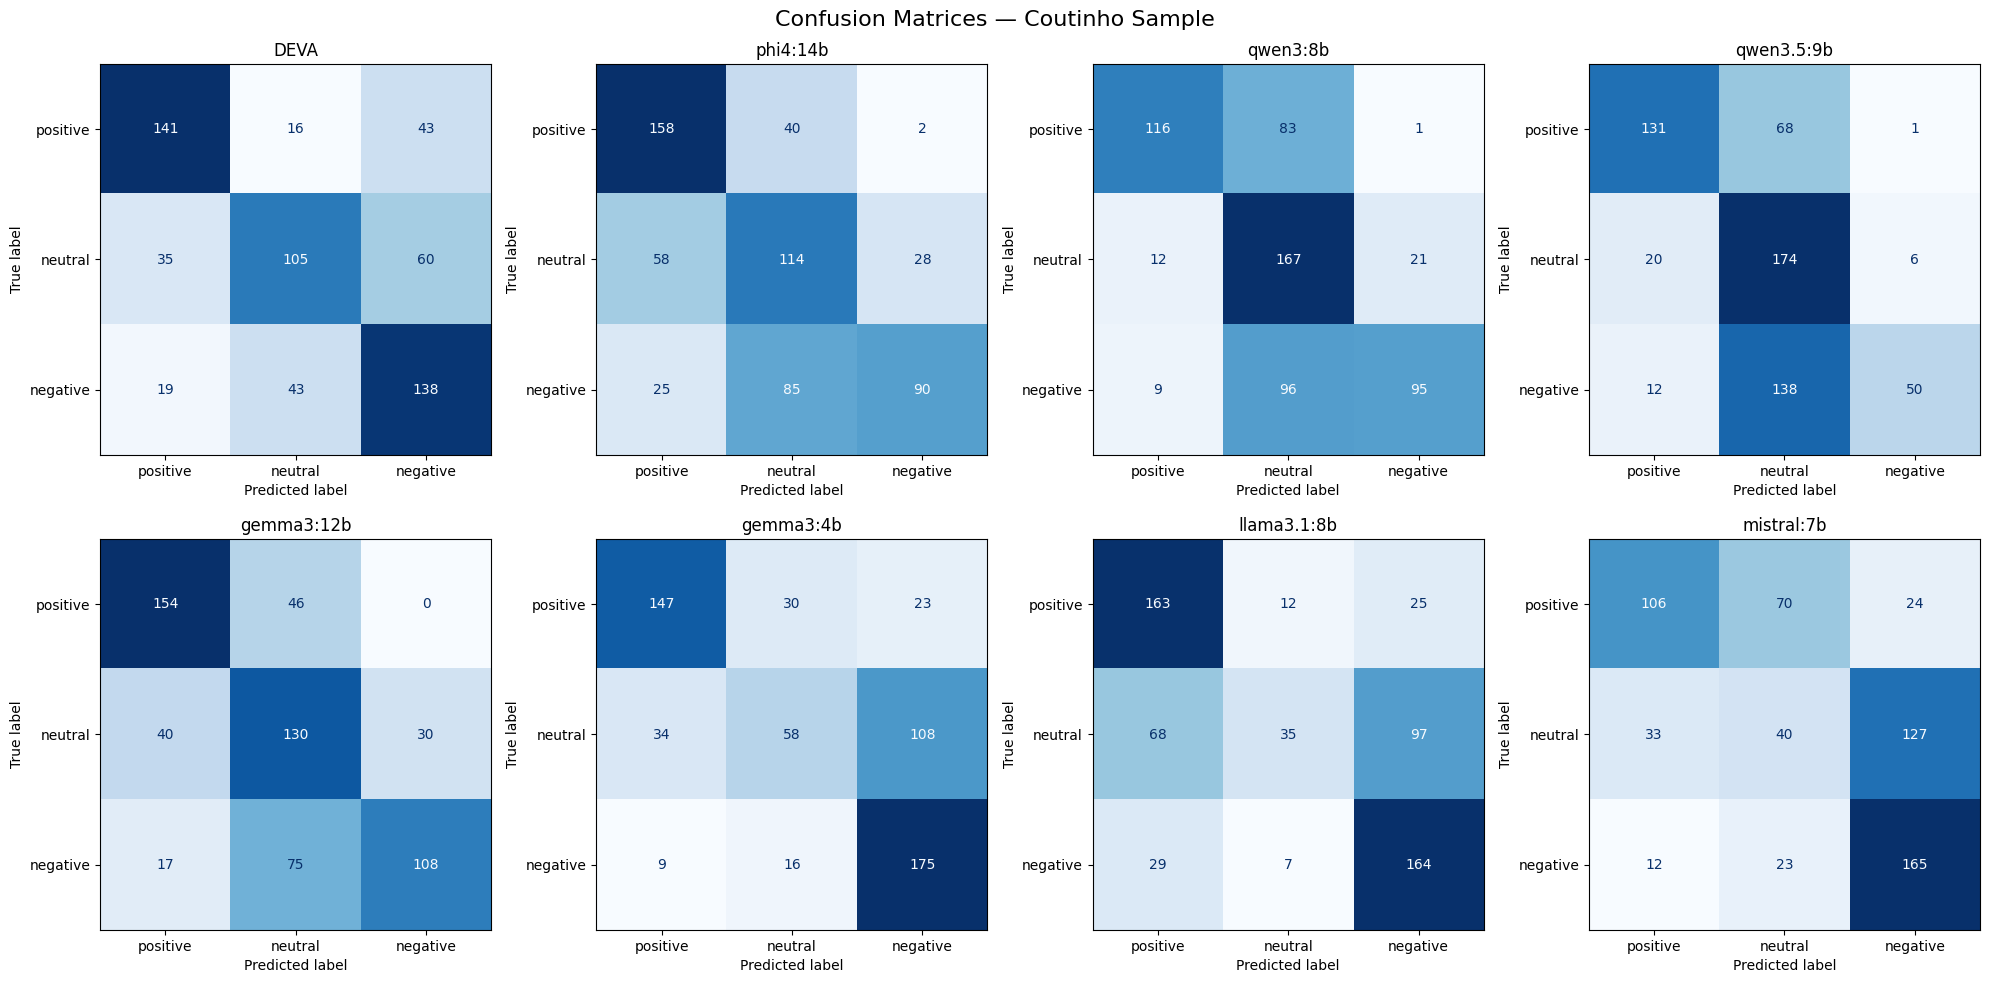

In [60]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

cm = confusion_matrix(df_merged_cou_sample['polarity'],                                                                                         
                      df_merged_cou_sample['deva_polarity'], labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)                                                                                        
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('DEVA')

for i, model in enumerate(models):
    cm = confusion_matrix(df_sample_cou['polarity'],
                          df_sample_cou[f'{model}_polarity'], labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    disp.plot(ax=axes[i + 1], cmap='Blues', colorbar=False)
    axes[i + 1].set_title(model)

fig.suptitle('Confusion Matrices — Coutinho Sample', fontsize=16)
plt.tight_layout()
fig.savefig('../output/confusion_matrices_coutinho.png', dpi=150, bbox_inches='tight')
plt.show()